**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 6**
Ingeniería de características (FE)

---

**Nombre:** 
Carla Naiely Perez A01285695

Hector Javier Pequeno Chairez A01246364

Iara Pérez Pineda A01705855

**Actividad 6: Ingeniería de características**

En esta actividad trabajarás con el archivo `computer_prices.csv`, basado en un conjunto de datos sobre características técnicas y especificaciones de computadoras portátiles y de escritorio, disponible en Kaggle.

Los datos fueron recopilados para analizar el rendimiento y el precio de los dispositivos, e incluyen información sobre hardware, almacenamiento, conectividad y otras especificaciones técnicas. Los indicadores incluidos son:

* `device_type`: Tipo de dispositivo (ej. laptop, desktop)
* `brand`: Marca del dispositivo
* `model`: Modelo del dispositivo
* `release_year`: Año de lanzamiento del dispositivo
* `os`: Sistema operativo instalado
* `form_factor`: Factor de forma o diseño del dispositivo (ej. laptop, ultrabook, desktop tower)
* `cpu_brand`: Marca del procesador
* `cpu_tier`: Nivel o gama del procesador, ordinal del 1 al 6 según desempeño
* `cpu_cores`: Número de núcleos del procesador
* `cpu_threads`: Número de hilos de ejecución del procesador
* `gpu_brand`: Marca de la tarjeta gráfica
* `gpu_model`: Modelo específico de la tarjeta gráfica
* `gpu_tier`: Nivel o gama de la GPU, ordinal del 1 al 6 según desempeño
* `vram_gb`: Memoria de video de la GPU en gigabytes
* `ram_gb`: Memoria RAM del dispositivo en gigabytes
* `storage_type`: Tipo de almacenamiento (ej. HDD, SSD)
* `storage_gb`: Capacidad de almacenamiento en gigabytes
* `storage_drive_count`: Número de unidades de almacenamiento instaladas
* `display_type`: Tipo de pantalla (ej. IPS, TN, OLED)
* `charger_watts`: Potencia del cargador (en watts) para laptops
* `psu_watts`: Potencia de la fuente de poder (en watts) para desktops
* `wifi`: Estándar de conectividad Wi-Fi (ej. Wi-Fi 5, 6, 6E, 7)
* `bluetooth`: Versión de Bluetooth
* `weight_kg`: Peso del dispositivo en kilogramos
* `warranty_months`: Meses de garantía del dispositivo
* `price`: Precio del dispositivo. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

**Preparación.** Utilizo el archivo `computer_prices.csv` en la misma carpeta que esta libreta. En Colab debo cargarlo al directorio de trabajo. Instalo únicamente las dependencias que falten y ejecuto todas las celdas en orden.

In [1]:
import importlib.util
import subprocess
import sys
paquetes = {'pandas': 'pandas', 'numpy': 'numpy', 'matplotlib': 'matplotlib',
            'seaborn': 'seaborn', 'scipy': 'scipy', 'sklearn': 'scikit-learn',
            'category_encoders': 'category_encoders'}
faltantes = [paquete for modulo, paquete in paquetes.items()
             if importlib.util.find_spec(modulo) is None]
if faltantes:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *faltantes])

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import inspect
from datetime import date
from scipy.stats import probplot
from sklearn.preprocessing import (KBinsDiscretizer, FunctionTransformer,
                                   PowerTransformer, MinMaxScaler,
                                   OneHotEncoder, OrdinalEncoder)
from category_encoders.binary import BinaryEncoder
from IPython.display import display
sns.set_theme(style='whitegrid')
pd.set_option('display.max_rows', 100)
%matplotlib inline

1. Descarga el archivo: `computer_prices.csv` y guarda, en un dataframe (`compu_df`), todos sus registros.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.
* Elimina las variables:
  * `model`: Debido a su altísima cardinalidad, lo que dificulta su uso en análisis y modelado.
  * `cpu_model`: Además de su elevada cardinalidad, su información ya está representada de manera implícita en otras variables como: `cpu_tier`, `cpu_cores` y `cpu_threads`

In [3]:
compu_df = pd.read_csv('computer_prices.csv')
compu_df.info()
display(pd.Series({'Registros': len(compu_df),
                   'Columnas numéricas': len(compu_df.select_dtypes(include='number').columns),
                   'Columnas de texto': len(compu_df.select_dtypes(exclude='number').columns)}))
display(compu_df.nunique().rename('Valores únicos').to_frame())
compu_df = compu_df.drop(columns=['model', 'cpu_model'])

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 27 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   device_type          100000 non-null  str    
 1   brand                100000 non-null  str    
 2   model                100000 non-null  str    
 3   release_year         100000 non-null  int64  
 4   os                   100000 non-null  str    
 5   form_factor          100000 non-null  str    
 6   cpu_brand            100000 non-null  str    
 7   cpu_model            100000 non-null  str    
 8   cpu_tier             100000 non-null  int64  
 9   cpu_cores            100000 non-null  int64  
 10  cpu_threads          100000 non-null  int64  
 11  gpu_brand            100000 non-null  str    
 12  gpu_model            100000 non-null  str    
 13  gpu_tier             100000 non-null  int64  
 14  vram_gb              100000 non-null  int64  
 15  ram_gb               100000 n

Registros             100000
Columnas numéricas        15
Columnas de texto         12
dtype: int64

,Valores únicos
device_type,2
brand,10
model,99036
release_year,8
os,4
form_factor,10
cpu_brand,3
cpu_model,26971
cpu_tier,6
cpu_cores,12


Identifico **100,000 registros y 27 columnas: 15 numéricas y 12 de texto**, de acuerdo con `info()`. Encuentro 12 columnas enteras y 3 de punto flotante; `bluetooth` se lee como numérica aunque representa una versión.

Encuentro **99,036 valores únicos en `model` y 26,971 en `cpu_model`**. Elimino ambas variables siguiendo la consigna y conservo 25 columnas. Mantengo la marca, gama (`cpu_tier`), núcleos (`cpu_cores`) e hilos (`cpu_threads`) para resumir las características del procesador. Reconozco que estos atributos no representan completamente la arquitectura o generación que podría identificar mediante el modelo.

2. Antes de iniciar con el análisis univariado, verifica si hay valores duplicados y/o faltantes.
* Obtén las estadísticas descriptivas, separado las numéricas y las categóricas. De estas últimas incluye las tablas de frecuencia.
* Genera histogramas para las numéricas y diagramas de barras para las categóricas. Con alta cardinalidad, sólo incluye los 10 valores más frecuentes.

Filas duplicadas     0
Valores faltantes    0
dtype: int64

,Faltantes
device_type,0
brand,0
release_year,0
os,0
form_factor,0
cpu_brand,0
cpu_tier,0
cpu_cores,0
cpu_threads,0
gpu_brand,0


,count,mean,std,min,25%,50%,75%,max
release_year,100000.0,2022.320850,2.025761,2018.00,2021.00,2023.00,2024.00,2025.00
cpu_tier,100000.0,3.153490,1.373175,1.00,2.00,3.00,4.00,6.00
cpu_cores,100000.0,10.515740,5.044092,4.00,6.00,8.00,14.00,28.00
cpu_threads,100000.0,19.372700,9.718426,4.00,12.00,16.00,24.00,56.00
gpu_tier,100000.0,2.991350,1.459643,1.00,2.00,3.00,4.00,6.00
vram_gb,100000.0,6.152180,3.964926,0.00,4.00,6.00,8.00,16.00
ram_gb,100000.0,39.706400,31.902684,8.00,16.00,32.00,64.00,144.00
storage_gb,100000.0,903.936000,774.243654,256.00,512.00,512.00,1024.00,4096.00
storage_drive_count,100000.0,1.524980,0.797284,1.00,1.00,1.00,2.00,4.00
charger_watts,100000.0,61.383450,62.795034,0.00,0.00,65.00,90.00,240.00


,count,unique,top,freq
device_type,100000,2,Laptop,59844
brand,100000,10,Lenovo,15992
os,100000,4,Windows,71817
form_factor,100000,10,Mainstream,17819
cpu_brand,100000,3,Intel,52774
gpu_brand,100000,4,NVIDIA,54712
gpu_model,100000,49,Apple Integrated,18922
storage_type,100000,4,NVMe,45059
display_type,100000,6,LED,32000
wifi,100000,4,Wi-Fi 6,46149


,Frecuencia,Porcentaje
device_type,,
Laptop,59844,59.844
Desktop,40156,40.156


...

,Frecuencia,Porcentaje
gpu_brand,,
NVIDIA,54712,54.712
Apple,18922,18.922
AMD,15767,15.767
Intel,10599,10.599


,Frecuencia,Porcentaje
gpu_model,,
Apple Integrated,18922,18.922
RTX 40 70,5743,5.743
RTX 30 70,5692,5.692
RTX 40 60,5437,5.437
RTX 30 60,5314,5.314
RTX 30 50,5046,5.046
RTX 40 50,4970,4.970
RTX 40 80,4676,4.676
RTX 30 80,4618,4.618


,Frecuencia,Porcentaje
storage_type,,
NVMe,45059,45.059
SSD,24937,24.937
HDD,15023,15.023
Hybrid,14981,14.981


,Frecuencia,Porcentaje
display_type,,
LED,32000,32.000
OLED,21910,21.910
IPS,17742,17.742
Mini-LED,12188,12.188
QLED,10069,10.069
VA,6091,6.091


,Frecuencia,Porcentaje
wifi,,
Wi-Fi 6,46149,46.149
Wi-Fi 6E,25923,25.923
Wi-Fi 5,19926,19.926
Wi-Fi 7,8002,8.002


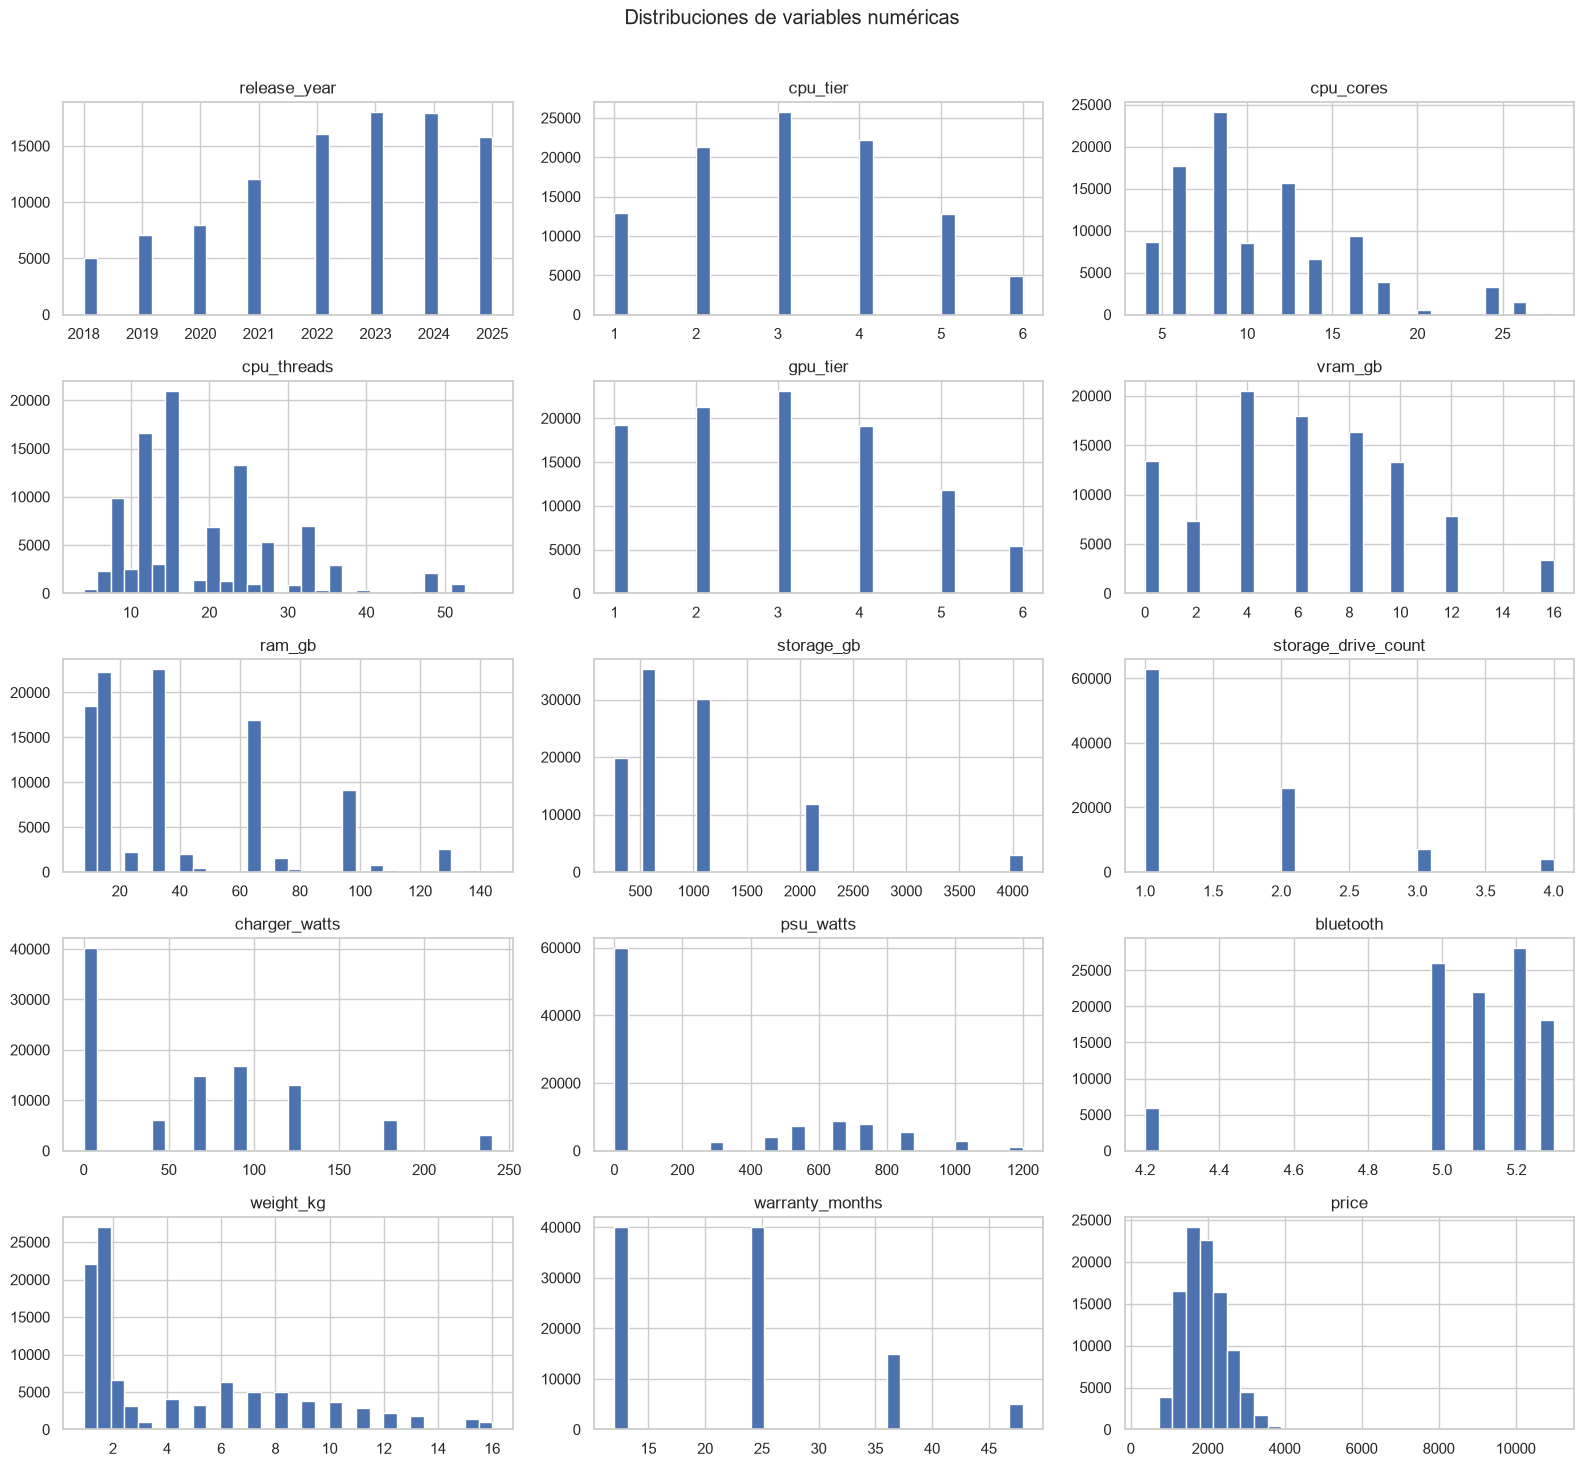

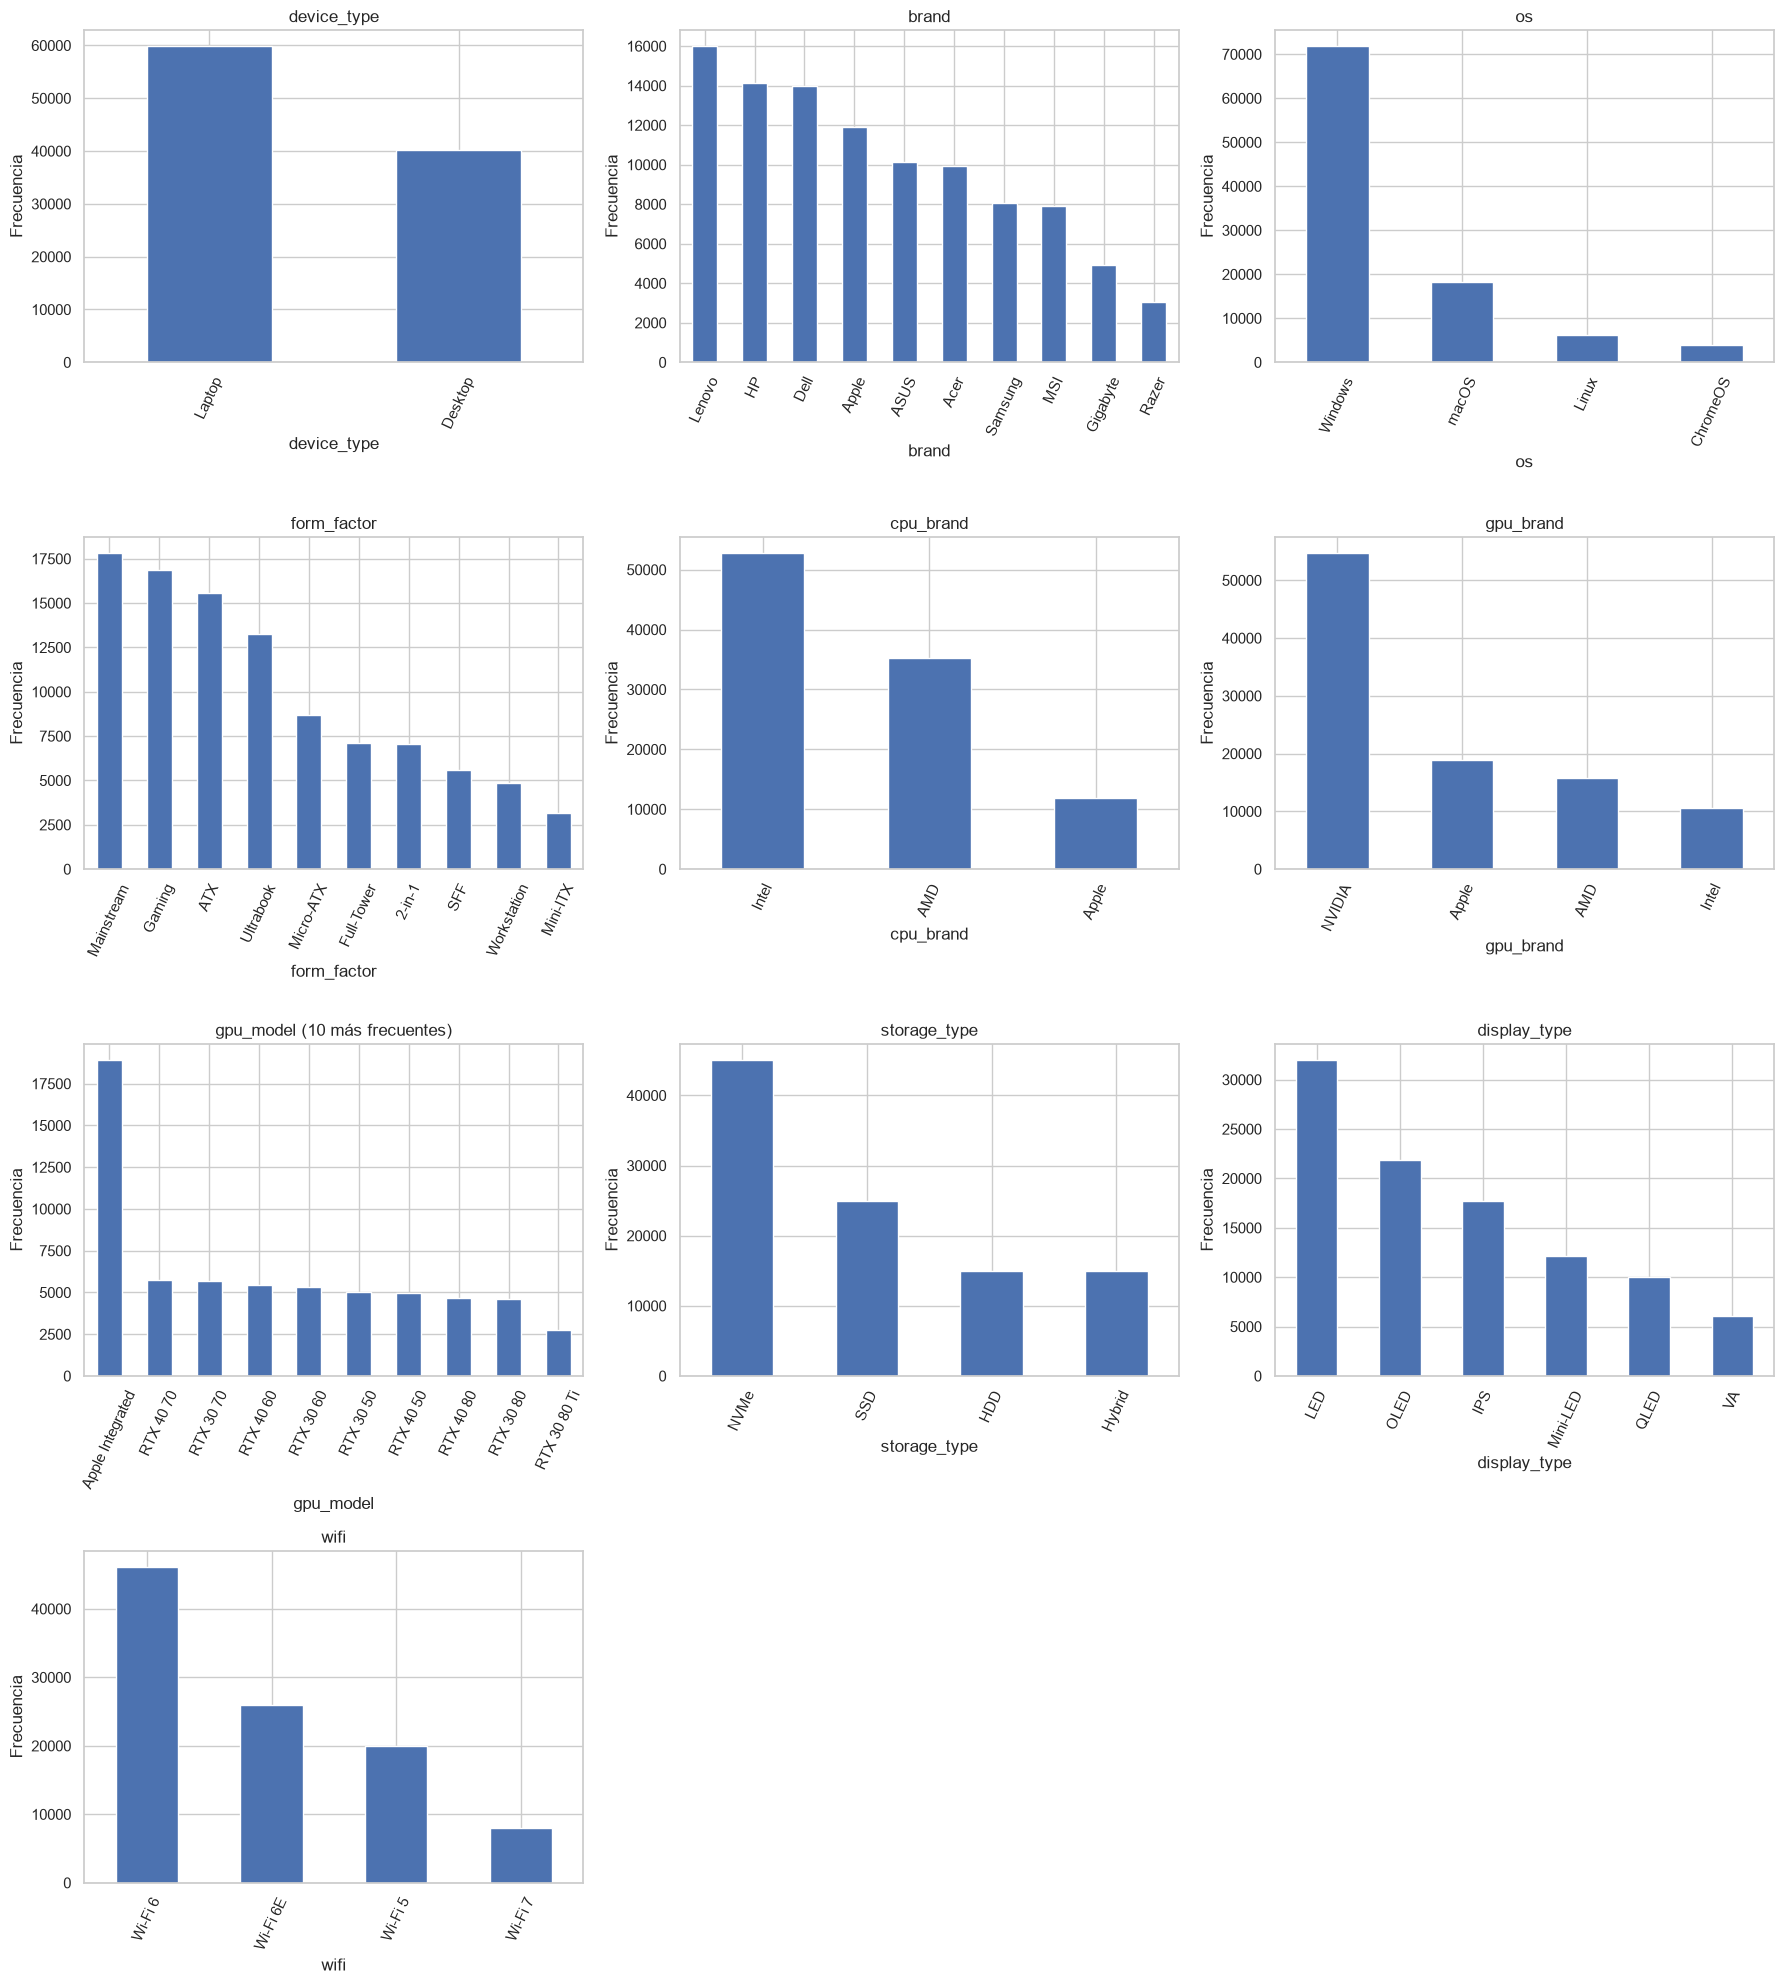

In [4]:
display(pd.Series({'Filas duplicadas': compu_df.duplicated().sum(),
                   'Valores faltantes': compu_df.isna().sum().sum()}))
display(compu_df.isna().sum().rename('Faltantes').to_frame())
num_cols = compu_df.select_dtypes(include='number').columns
cat_cols = compu_df.select_dtypes(exclude='number').columns
display(compu_df[num_cols].describe().T)
display(compu_df[cat_cols].describe().T)
for columna in cat_cols:
    frecuencia = compu_df[columna].value_counts(dropna=False)
    display(pd.DataFrame({'Frecuencia': frecuencia,
                          'Porcentaje': frecuencia / len(compu_df) * 100}).rename_axis(columna))
compu_df[num_cols].hist(bins=30, figsize=(16, 17), layout=(6, 3))
plt.suptitle('Distribuciones de variables numéricas', y=1.01)
plt.tight_layout()
plt.show()
filas_cat = int(np.ceil(len(cat_cols) / 3))
fig, axes = plt.subplots(filas_cat, 3, figsize=(18, 5 * filas_cat))
for ax, columna in zip(axes.flat, cat_cols):
    compu_df[columna].value_counts().head(10).plot.bar(ax=ax)
    ax.set_title(columna + (' (10 más frecuentes)' if compu_df[columna].nunique() > 10 else ''))
    ax.set_ylabel('Frecuencia')
    ax.tick_params(axis='x', rotation=65)
for ax in axes.flat[len(cat_cols):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

No encuentro duplicados ni valores faltantes en el dataframe de este paso, por lo que conservo los 100,000 registros. Presento estadísticas numéricas y categóricas por separado y tablas de frecuencias y porcentajes para todas las categorías.

Observo un precio medio de **1928.76**, mediana de **1863.99** y máximo de **10984.99**, compatibles con una cola hacia precios altos. Identifico predominio de laptops (**59.844%**), Windows (**71.817%**) y Wi-Fi 6 (**46.149%**). En los histogramas interpreto el eje horizontal como los valores y el vertical como la cantidad de equipos por intervalo. En las barras comparo frecuencias por categoría.

Incluyo gráficas para las diez variables categóricas, incluida `wifi`. Para `gpu_model` muestro solo las diez categorías más frecuentes en la gráfica, aunque incluyo todas en la tabla. Analizo los ceros de las potencias en el punto 5.

3. Dibuja un mapa de calor con la matriz de correlación para las variables numéricas del conjunto de datos.
* Identifica los pares de variables cuya correlación sea superior a 0.9 e imprímelos.
* Reflexiona sobre cuáles variables, de las que se imprimieron, representan de manera general la capacidad del hardware y mantenlas; elimina las demás por aportar información redundante.
* Incluye una breve justificación de tus decisiones.

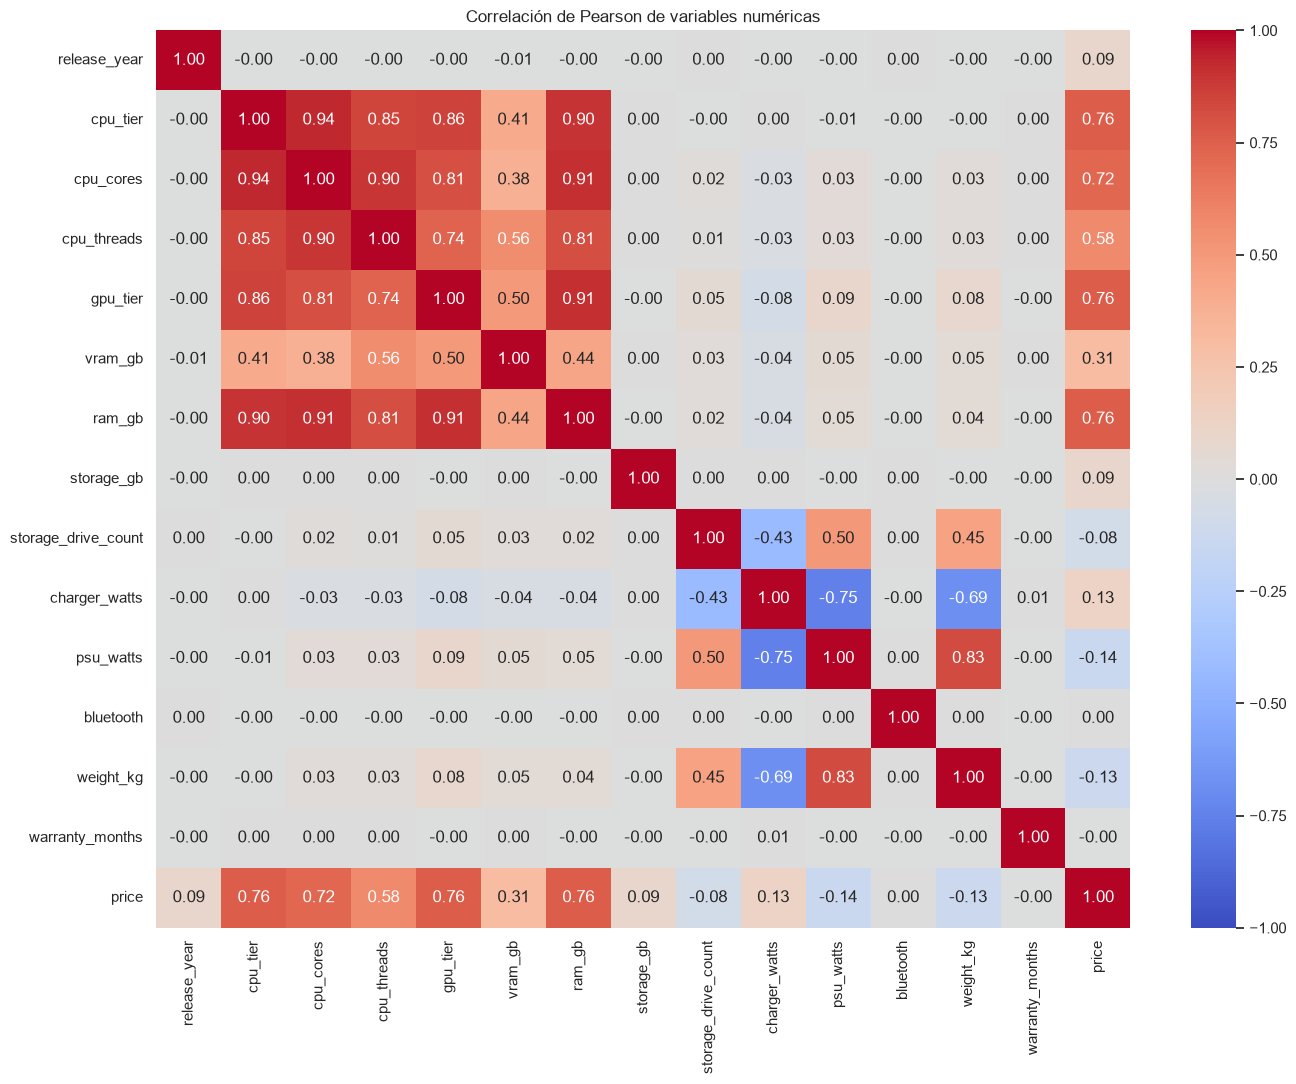

cpu_tier   cpu_cores    0.937376
cpu_cores  ram_gb       0.906770
gpu_tier   ram_gb       0.912918


In [5]:
correlacion = compu_df.corr(numeric_only=True)
plt.figure(figsize=(14, 11))
sns.heatmap(correlacion, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlación de Pearson de variables numéricas')
plt.tight_layout()
plt.show()
triangulo = correlacion.where(np.triu(np.ones(correlacion.shape), k=1).astype(bool))
pares = triangulo.stack().rename('Correlación')
pares_altos = pares[pares > 0.9]
print(pares_altos.to_string())
compu_df = compu_df.drop(columns=['cpu_cores', 'ram_gb'])

Identifico tres pares con correlación superior a 0.9: `cpu_tier`–`cpu_cores` (**0.9374**), `cpu_cores`–`ram_gb` (**0.9068**) y `gpu_tier`–`ram_gb` (**0.9129**). Interpreto valores próximos a 1 en el mapa de calor como asociaciones lineales positivas fuertes.

Conservo **cpu_tier y gpu_tier** porque resumen la gama general del hardware. Elimino **cpu_cores y ram_gb** para reducir la redundancia observada y quedan 23 columnas. Reconozco que la RAM tiene significado propio y que su correlación con la GPU no demuestra causalidad. Sigo el criterio exploratorio de la actividad y evaluaría esta selección al construir un modelo. Mantengo `cpu_threads`, que no supera el umbral, y `vram_gb`, necesaria en el siguiente ejercicio.

4. Para comenzar con la ingeniería de características, crea una copia del dataframe y asígnala a un nuevo objeto llamado `compu_transf`.
* Calcula cuántos años han pasado desde el lanzamiento de cada computadora y almacénalo en una nueva columna llamada `years_since_release`; luego, elimina la columna original.
* Utiliza `KBinsDiscretizer` para reemplazar la columna `vram_gb` en 4 bins ordinales basados en cuantiles.
* Imprime los valores que delimitan cada bin y haz un gráfico de barras para ver la cantidad de observaciones en cada uno, con el fin de entender cómo se agruparon los datos.

Año de referencia: 2026
Límites de los bins: [ 0.  4.  6.  8. 16.]


,Bin,Límite inferior,Límite superior
0,0,0.0,4.0
1,1,4.0,6.0
2,2,6.0,8.0
3,3,8.0,16.0


,Frecuencia
vram_gb,
0.0,20757
1.0,20517
2.0,17930
3.0,40796


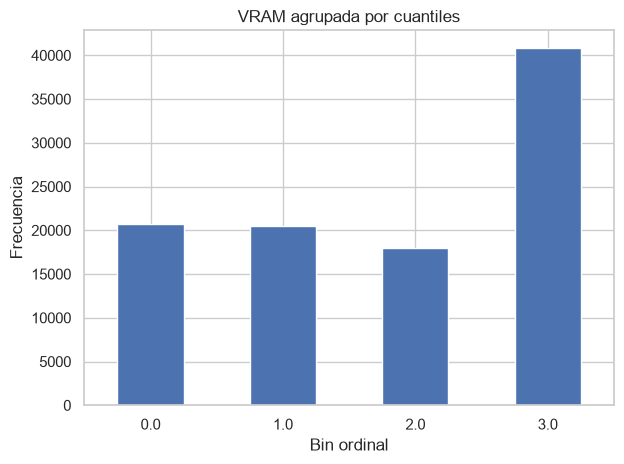

In [6]:
compu_transf = compu_df.copy()
anio_actual = date.today().year
compu_transf['years_since_release'] = anio_actual - compu_transf['release_year']
compu_transf = compu_transf.drop(columns='release_year')
print('Año de referencia:', anio_actual)
parametros_bins = dict(n_bins=4, encode='ordinal', strategy='quantile', subsample=None)
if 'quantile_method' in inspect.signature(KBinsDiscretizer).parameters:
    parametros_bins['quantile_method'] = 'linear'
discretizador = KBinsDiscretizer(**parametros_bins)
compu_transf['vram_gb'] = discretizador.fit_transform(compu_transf[['vram_gb']]).ravel()
limites = discretizador.bin_edges_[0]
print('Límites de los bins:', limites)
display(pd.DataFrame({'Bin': range(4), 'Límite inferior': limites[:-1],
                      'Límite superior': limites[1:]}))
conteos_bins = compu_transf['vram_gb'].value_counts().sort_index()
display(conteos_bins.rename('Frecuencia').to_frame())
conteos_bins.plot.bar(rot=0, title='VRAM agrupada por cuantiles')
plt.xlabel('Bin ordinal')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

Creo `compu_transf` como copia y calculo la antigüedad restando el año de lanzamiento al año de ejecución (2026 en esta entrega). Reemplazo `release_year` por `years_since_release`.

Obtengo los intervalos de VRAM **[0, 4), [4, 6), [6, 8) y [8, 16]**, codificados de 0 a 3. Incluyo el extremo con corchete y excluyo el extremo con paréntesis: asigno 4 GB al segundo intervalo. Encuentro **20,757; 20,517; 17,930 y 40,796** equipos, respectivamente. No obtengo exactamente 25% por grupo porque existen valores repetidos; no separo equipos con la misma VRAM entre intervalos distintos.

5. Observa los histogramas del ejercicio 2. Notarás que en las variables `charger_watts` y `psu_watts` aparece una barra en 0. Analiza por qué ocurre esto y qué significa en relación con el tipo de dispositivo.
* Como estas variables son mutuamente excluyentes, combínalas en una nueva columna llamada `power_watts` que contenga la potencia correspondiente de cada dispositivo y, a continuación, haz un histograma para verificar que la distribución resultante es bimodal.
* Por último, borra las columnas originales `charger_watts` y `psu_watts`.

charger_watts      psu_watts      
                      min  max       min   max
device_type                                   
Desktop                 0    0       300  1200
Laptop                 45  240         0     0

Cargador igual a cero,False,True
device_type,,
Desktop,0,40156
Laptop,59844,0


Fuente igual a cero,False,True
device_type,,
Desktop,40156,0
Laptop,0,59844


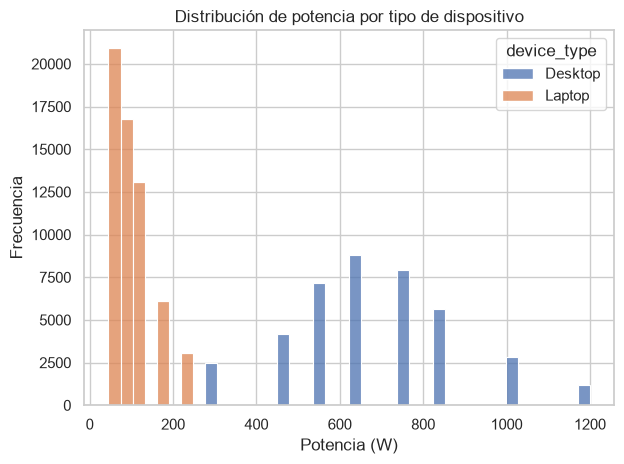

In [7]:
display(compu_transf.groupby('device_type')[['charger_watts', 'psu_watts']].agg(['min', 'max']))
display(pd.crosstab(compu_transf['device_type'], compu_transf['charger_watts'].eq(0),
                    colnames=['Cargador igual a cero']))
display(pd.crosstab(compu_transf['device_type'], compu_transf['psu_watts'].eq(0),
                    colnames=['Fuente igual a cero']))
assert ((compu_transf['charger_watts'] > 0) ^ (compu_transf['psu_watts'] > 0)).all()
compu_transf['power_watts'] = compu_transf['charger_watts'] + compu_transf['psu_watts']
sns.histplot(data=compu_transf, x='power_watts', hue='device_type', bins=40, multiple='stack')
plt.title('Distribución de potencia por tipo de dispositivo')
plt.xlabel('Potencia (W)')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()
compu_transf = compu_transf.drop(columns=['charger_watts', 'psu_watts'])

Interpreto los ceros como **no aplica**: encuentro `charger_watts = 0` en desktops y `psu_watts = 0` en laptops. No los considero faltantes ni equipos sin consumo. Compruebo que solo una potencia sea positiva por fila, sumo ambas en `power_watts` y elimino las columnas originales.

Distingo dos regiones de concentración en el histograma: laptops de **45 a 240 W** y desktops de **300 a 1200 W**. Identifico la estructura de dos grupos que motiva la bimodalidad solicitada. Como las potencias son discretas, también encuentro picos internos; no interpreto el histograma como una curva suave con exactamente dos máximos. Trabajo con la potencia nominal del cargador o fuente, no con consumo instantáneo medido.

6. Para disminuir el sesgo de la variable `price`, crea tres transformadores: logaritmo, raíz cuadrada y Box - Cox.
* Aplica cada transformador a la variable price, dejando el resultado en variables temporales. El objetivo es comparar los efectos de cada transformación antes de decidir cuál aplicar de manera definitiva sobre las variables continuas del dataframe.
* De la variable original y de cada una de las tres transformaciones se debe mostrar:
  * Histograma: para observar la distribución de los datos.
  * Boxplot: para identificar posibles valores atípicos.
  * Q-Q plot: para evaluar la normalidad de la variable.
  * Skew (sesgo): para cuantificar la asimetría de la distribución.
  * Cantidad de outliers: para conocer cuántos valores extremos existen.
* En función de los resultados obtenidos al comparar las transformaciones, decide cuál logró el mejor efecto sobre la distribución de la variable y aplícala directamente en el dataframe, reemplazando las variables continuas: `weight_kg`, `power_watts` y `price`.

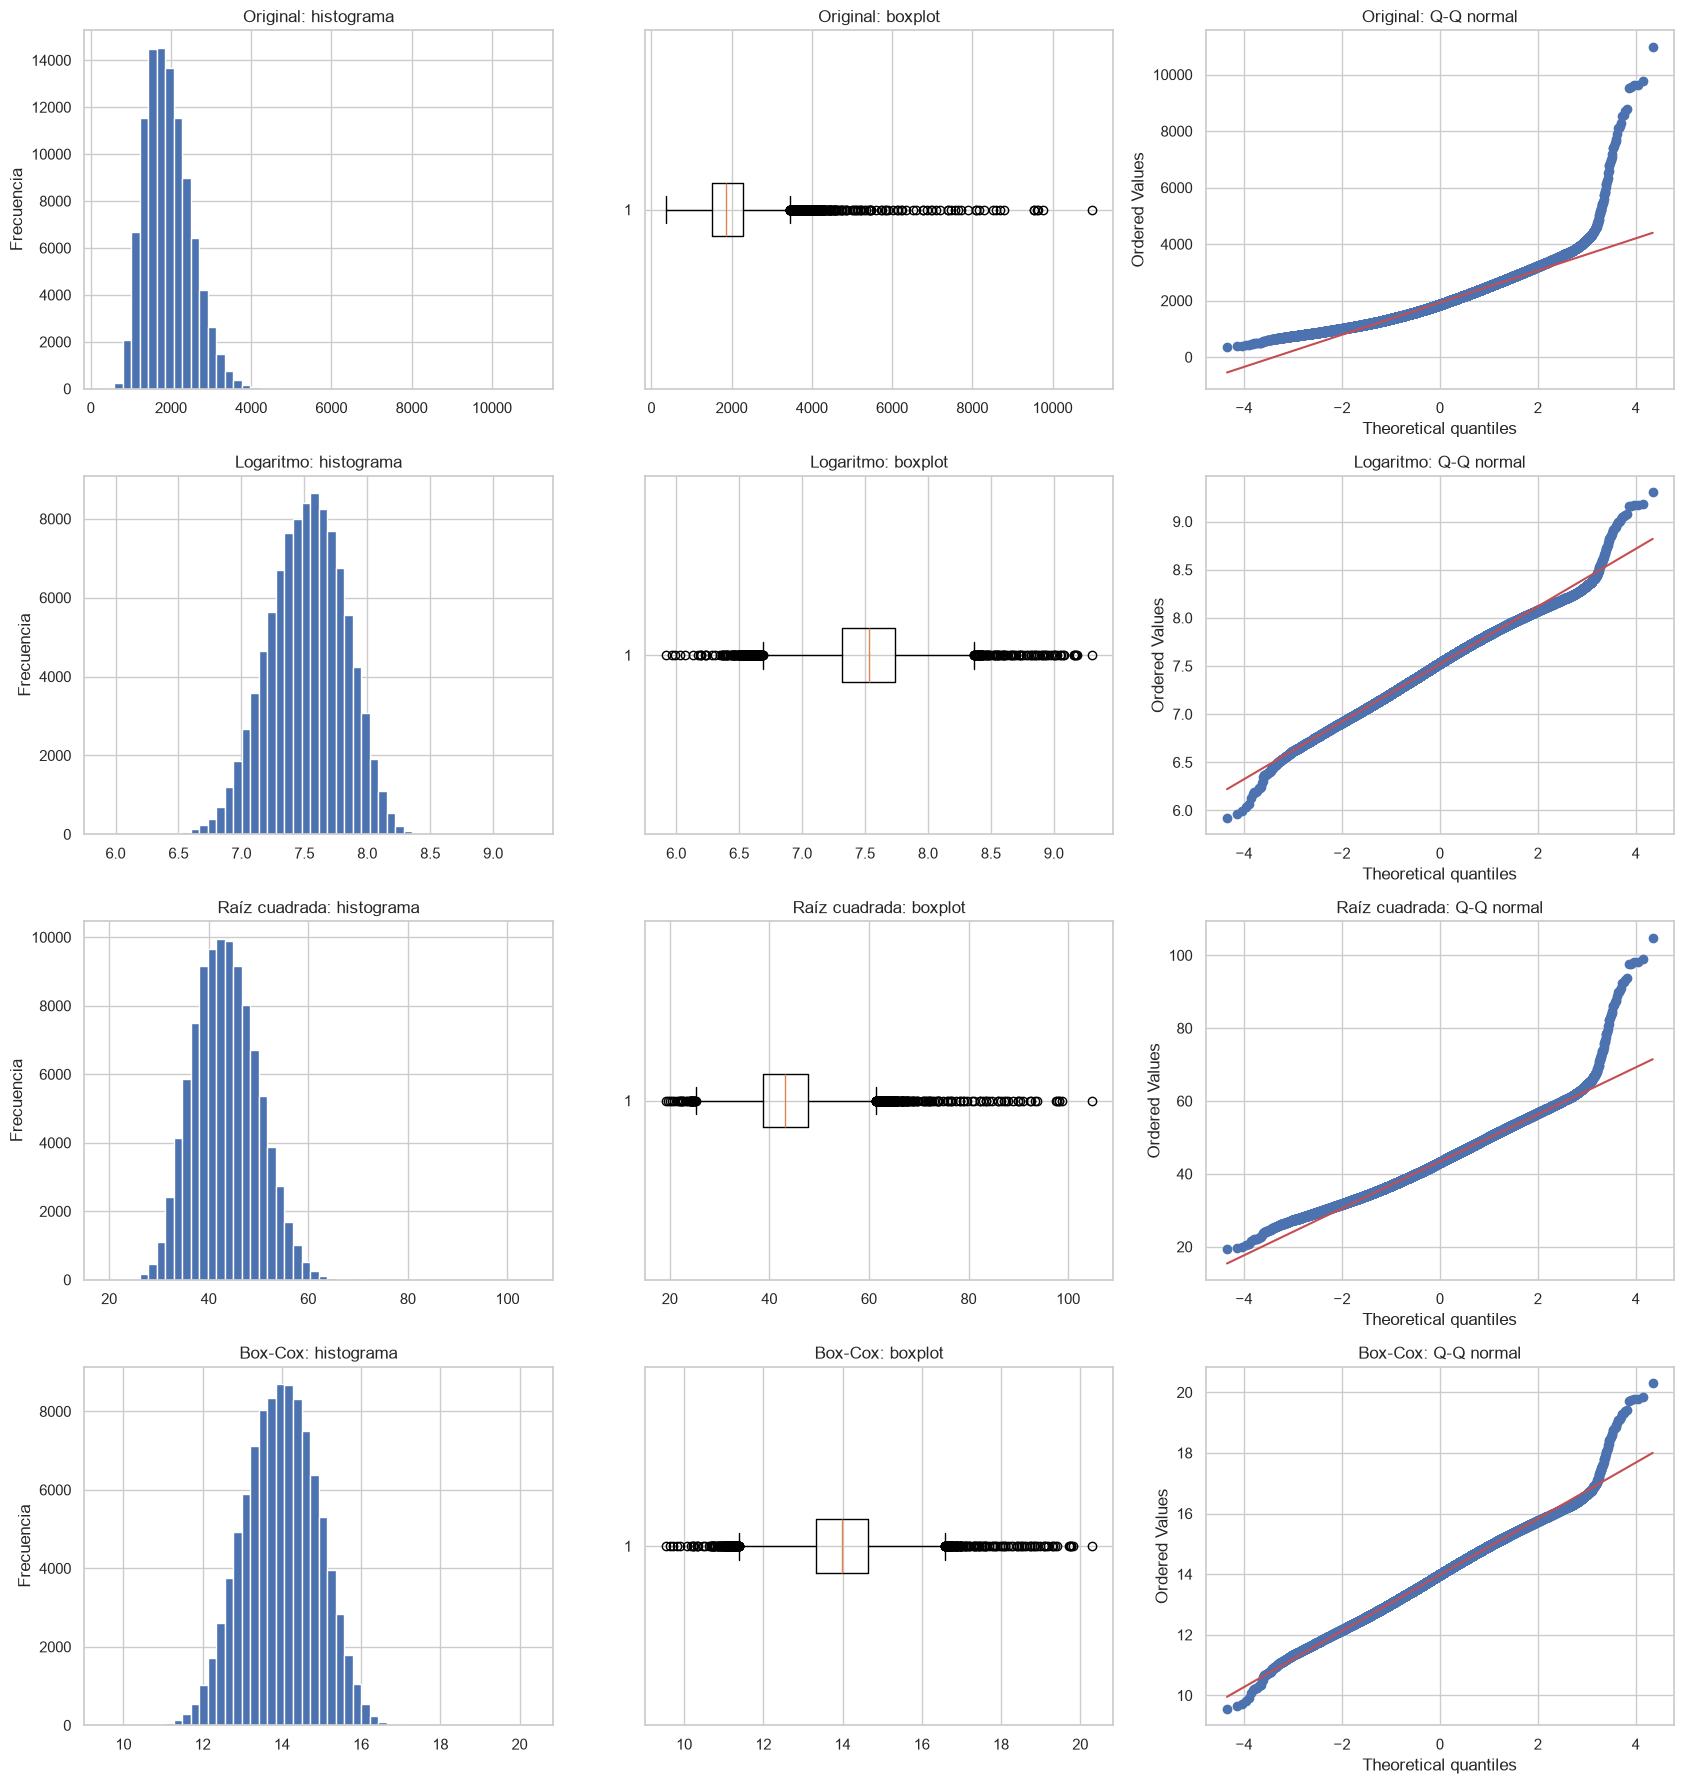

,Sesgo,Valores atípicos
Transformación,,
Original,0.986644,976
Logaritmo,-0.133105,386
Raíz cuadrada,0.332253,364
Box-Cox,-0.000238,317


Lambda de Box-Cox para price: 0.15041806876928954


In [8]:
precio = compu_transf[['price']]
assert (precio > 0).all().all()
transformador_log = FunctionTransformer(np.log, inverse_func=np.exp)
transformador_raiz = FunctionTransformer(np.sqrt, inverse_func=np.square)
transformador_boxcox = PowerTransformer(method='box-cox', standardize=False)
versiones_precio = {
    'Original': precio.to_numpy().ravel(),
    'Logaritmo': transformador_log.fit_transform(precio).to_numpy().ravel(),
    'Raíz cuadrada': transformador_raiz.fit_transform(precio).to_numpy().ravel(),
    'Box-Cox': transformador_boxcox.fit_transform(precio).ravel()
}
resultados = []
fig, axes = plt.subplots(4, 3, figsize=(17, 18))
for fila, (nombre, valores) in enumerate(versiones_precio.items()):
    q1, q3 = np.quantile(valores, [0.25, 0.75])
    iqr = q3 - q1
    atipicos = ((valores < q1 - 1.5 * iqr) | (valores > q3 + 1.5 * iqr)).sum()
    resultados.append({'Transformación': nombre, 'Sesgo': pd.Series(valores).skew(),
                       'Valores atípicos': int(atipicos)})
    axes[fila, 0].hist(valores, bins=50)
    axes[fila, 0].set_title(nombre + ': histograma')
    axes[fila, 0].set_ylabel('Frecuencia')
    axes[fila, 1].boxplot(valores, orientation='horizontal')
    axes[fila, 1].set_title(nombre + ': boxplot')
    probplot(valores, dist='norm', plot=axes[fila, 2])
    axes[fila, 2].set_title(nombre + ': Q-Q normal')
plt.tight_layout()
plt.show()
comparacion = pd.DataFrame(resultados).set_index('Transformación')
display(comparacion)
print('Lambda de Box-Cox para price:', transformador_boxcox.lambdas_[0])

Comparo las transformaciones en variables temporales antes de modificar el dataframe. Con el logaritmo natural comprimo los valores altos; con la raíz cuadrada los comprimo de manera más moderada. Con Box-Cox ajusto una potencia mediante **lambda**: uso `(x**lambda - 1) / lambda` si lambda es distinto de cero y `log(x)` si es cero. Obtengo lambda mediante el ajuste del transformador; no lo interpreto como correlación.

Leo las cuatro filas de gráficas en el orden original, logaritmo, raíz cuadrada y Box-Cox:
- En los **histogramas** comparo concentración y colas. Identifico asimetría positiva en el original; con el logaritmo obtengo una ligera asimetría negativa, con la raíz mantengo asimetría positiva y con Box-Cox la reduzco más.
- En los **boxplots** interpreto la caja como el 50% central y su línea interna como la mediana. Cuento posibles atípicos fuera de Q1 − 1.5 × IQR y Q3 + 1.5 × IQR, donde IQR = Q3 − Q1.
- En los **Q-Q plots** comparo cuantiles observados con cuantiles normales. Interpreto la cercanía a la recta como apoyo a la aproximación normal y las desviaciones en los extremos como diferencias en las colas. No concluyo normalidad únicamente porque el sesgo esté cerca de cero.

Obtengo esta comparación:

| Versión | Sesgo | Posibles atípicos |
|---|---:|---:|
| Original | 0.986644 | 976 |
| Logaritmo | −0.133105 | 386 |
| Raíz cuadrada | 0.332253 | 364 |
| Box-Cox | −0.000238 | 317 |

Elijo **Box-Cox** principalmente por su menor asimetría absoluta; el menor conteo de posibles atípicos respalda mi elección en este ejercicio. Recalculo los límites del boxplot en cada escala, por lo que no interpreto la reducción como eliminación de registros o corrección de errores. Conservo todas las observaciones.

Aplico Box-Cox a `weight_kg`, `power_watts` y `price` con un lambda propio para cada columna, después de comprobar que sean positivas. Utilizo `standardize=False` porque escalo en el punto 7. Sigo la consigna al extender la transformación elegida a peso y potencia; no supongo que la elección basada en precio garantice normalidad para esas otras variables.

In [9]:
continuas = ['weight_kg', 'power_watts', 'price']
assert (compu_transf[continuas] > 0).all().all()
boxcox_continuas = PowerTransformer(method='box-cox', standardize=False)
compu_transf[continuas] = boxcox_continuas.fit_transform(compu_transf[continuas])
display(pd.Series(boxcox_continuas.lambdas_, index=continuas, name='Lambda').to_frame())

,Lambda
weight_kg,-0.480424
power_watts,-0.165033
price,0.150418


7. Para que todas las variables numéricas estén en la misma escala, aplica `MinMaxScaler` de sklearn a todas las columnas numéricas del dataframe, reemplazando las columnas originales.

In [10]:
columnas_numericas = compu_transf.select_dtypes(include='number').columns
escalador_numerico = MinMaxScaler()
compu_transf[columnas_numericas] = escalador_numerico.fit_transform(compu_transf[columnas_numericas])
display(compu_transf[columnas_numericas].agg(['min', 'max']).T)

,min,max
cpu_tier,0.0,1.0
cpu_threads,0.0,1.0
gpu_tier,0.0,1.0
vram_gb,0.0,1.0
storage_gb,0.0,1.0
storage_drive_count,0.0,1.0
bluetooth,0.0,1.0
weight_kg,0.0,1.0
warranty_months,0.0,1.0
price,0.0,1.0


Aplico MinMaxScaler a todas las columnas numéricas mediante **(x − mínimo) / (máximo − mínimo)** y reemplazo sus valores originales. Compruebo mínimos de 0 y máximos de 1 dentro de la tolerancia numérica. Incluyo ordinales y `price`, según la consigna. Conservo el orden, pero no elimino asimetría con este escalamiento. Reconozco que peso, potencia y precio ya no están expresados en sus unidades originales.

8. Aunque `wifi` es una variable categórica, sus categorías tienen un orden natural (Wi-Fi 5 < Wi-Fi 6 < Wi-Fi 6E < Wi-Fi 7). Codifícala usando `OrdinalEncoder`.
* Luego, escala la variable codificada entre 0 y 1 con `MinMaxScaler`, para que quede en la misma escala que las variables numéricas del dataframe.

Nota: Ambos cambios deben efectuarse sobre la columna original, de manera que quede una única columna `wifi` con toda la información transformada.

In [11]:
orden_wifi = ['Wi-Fi 5', 'Wi-Fi 6', 'Wi-Fi 6E', 'Wi-Fi 7']
codificador_wifi = OrdinalEncoder(categories=[orden_wifi])
compu_transf['wifi'] = codificador_wifi.fit_transform(compu_transf[['wifi']]).ravel()
escalador_wifi = MinMaxScaler()
compu_transf['wifi'] = escalador_wifi.fit_transform(compu_transf[['wifi']]).ravel()
display(pd.DataFrame({'Categoría': orden_wifi, 'Código': range(4),
                      'Valor escalado': escalador_wifi.transform(pd.DataFrame({'wifi': range(4)})).ravel()}))

,Categoría,Código,Valor escalado
0,Wi-Fi 5,0,0.000000
1,Wi-Fi 6,1,0.333333
2,Wi-Fi 6E,2,0.666667
3,Wi-Fi 7,3,1.000000


Codifico **Wi-Fi 5 → 0; Wi-Fi 6 → 1; Wi-Fi 6E → 2; Wi-Fi 7 → 3** y después escalo para obtener **0, 1/3, 2/3 y 1** en una sola columna `wifi`.

Utilizo codificación ordinal para conservar el orden indicado. Podría usar One-Hot para tratarlas como categorías independientes, pero necesitaría varias columnas. Interpreto los decimales como códigos escalados; no representan porcentajes de velocidad ni incrementos de rendimiento igualmente espaciados.

9. La variable `gpu_model` tiene muchas categorías. Usar *One-Hot Encoding* aumentaría significativamente la dimensionalidad del dataframe. Por ello, utiliza `BinaryEncoder` para codificarla.
* Guarda el resultado en un dataframe llamado `bin_df`. Más adelante, lo combinarás con `compu_transf` para integrar las variables codificadas.

In [12]:
codificador_binario = BinaryEncoder(cols=['gpu_model'], return_df=True)
bin_df = codificador_binario.fit_transform(compu_transf[['gpu_model']])
display(bin_df.head())
print('Categorías originales:', compu_transf['gpu_model'].nunique())
print('Columnas binarias:', bin_df.shape[1])

,gpu_model_0,gpu_model_1,gpu_model_2,gpu_model_3,gpu_model_4,gpu_model_5
0,0,0,0,0,0,1
1,0,0,0,0,1,0
2,0,0,0,0,1,1
3,0,0,0,1,0,0
4,0,0,0,1,0,1


Categorías originales: 49
Columnas binarias: 6


Represento las **49 categorías** de `gpu_model` en **6 columnas binarias**, frente a 49 con One-Hot o 48 al eliminar una referencia. Guardo el resultado en `bin_df` y conservo el índice para alinear los equipos al combinar los dataframes.

Interpreto el patrón completo de bits como un código de categoría. Compartir un bit no implica que dos GPU tengan rendimiento parecido. Reduzco la cantidad de columnas necesarias para codificar el modelo y conservo todos los registros.

10. Usa `OneHotEncoder` para codificar las variables categóricas restantes. Asegúrate de usar `drop='first'` para evitar la multicolinealidad y guarda el resultado en un dataframe llamado `ohe_df`
* Combina el dataframe `compu_transf` con las variables categóricas que fueron codificadas en `bin_df` y `ohe_df`. No olvides eliminar las variables originales.
* Usa `describe()` sobre el dataframe resultante para corroborar que todas las columnas estén escaladas entre 0 y 1 y que no queden variables categóricas sin codificar.

In [13]:
categoricas_restantes = compu_transf.select_dtypes(exclude='number').columns.drop('gpu_model')
codificador_ohe = OneHotEncoder(drop='first', sparse_output=False, dtype=np.int64)
ohe_df = pd.DataFrame(
    codificador_ohe.fit_transform(compu_transf[categoricas_restantes]),
    columns=codificador_ohe.get_feature_names_out(categoricas_restantes),
    index=compu_transf.index
)
display(pd.DataFrame({
    'Variable': categoricas_restantes,
    'Categoría de referencia': [categorias[indice] for categorias, indice in
                               zip(codificador_ohe.categories_, codificador_ohe.drop_idx_)]
}))
assert bin_df.index.equals(compu_transf.index)
assert ohe_df.index.equals(compu_transf.index)
compu_transf = pd.concat([
    compu_transf.drop(columns=[*categoricas_restantes, 'gpu_model']),
    bin_df, ohe_df
], axis=1)
display(compu_transf.describe().T)
tolerancia = 1e-12
verificaciones = pd.Series({
    'Todas las columnas son numéricas': all(pd.api.types.is_numeric_dtype(t) for t in compu_transf.dtypes),
    'Sin valores faltantes': not compu_transf.isna().any().any(),
    'Todos los valores son finitos': np.isfinite(compu_transf.to_numpy()).all(),
    'Mínimos >= 0 (tolerancia numérica)': (compu_transf.min() >= -tolerancia).all(),
    'Máximos <= 1 (tolerancia numérica)': (compu_transf.max() <= 1 + tolerancia).all(),
    'Se conservan todos los registros': len(compu_transf) == 100000,
    'Nombres de columnas únicos': compu_transf.columns.is_unique
})
display(verificaciones.rename('Verificación').to_frame())
assert verificaciones.all()
print('Dimensiones finales:', compu_transf.shape)
display(compu_transf.head())

,Variable,Categoría de referencia
0,device_type,Desktop
1,brand,ASUS
2,os,ChromeOS
3,form_factor,2-in-1
4,cpu_brand,AMD
5,gpu_brand,AMD
6,storage_type,HDD
7,display_type,IPS


,count,mean,std,min,25%,50%,75%,max
cpu_tier,100000.0,0.430698,0.274635,0.0,0.200000,0.400000,0.600000,1.0
cpu_threads,100000.0,0.295629,0.186893,0.0,0.153846,0.230769,0.384615,1.0
gpu_tier,100000.0,0.398270,0.291929,0.0,0.200000,0.400000,0.600000,1.0
vram_gb,100000.0,0.595883,0.394170,0.0,0.333333,0.666667,1.000000,1.0
storage_gb,100000.0,0.168733,0.201626,0.0,0.066667,0.066667,0.200000,1.0
storage_drive_count,100000.0,0.174993,0.265761,0.0,0.000000,0.000000,0.333333,1.0
wifi,100000.0,0.406670,0.284834,0.0,0.333333,0.333333,0.666667,1.0
bluetooth,100000.0,0.804331,0.223616,0.0,0.727273,0.818182,0.909091,1.0
weight_kg,100000.0,0.517032,0.293982,0.0,0.280423,0.417162,0.834353,1.0
warranty_months,100000.0,0.283343,0.284219,0.0,0.000000,0.333333,0.333333,1.0


,Verificación
Todas las columnas son numéricas,True
Sin valores faltantes,True
Todos los valores son finitos,True
Mínimos >= 0 (tolerancia numérica),True
Máximos <= 1 (tolerancia numérica),True
Se conservan todos los registros,True
Nombres de columnas únicos,True


Dimensiones finales: (100000, 54)


,cpu_tier,cpu_threads,gpu_tier,vram_gb,storage_gb,storage_drive_count,wifi,bluetooth,weight_kg,warranty_months,...,gpu_brand_Intel,gpu_brand_NVIDIA,storage_type_Hybrid,storage_type_NVMe,storage_type_SSD,display_type_LED,display_type_Mini-LED,display_type_OLED,display_type_QLED,display_type_VA
0,0.4,0.384615,0.2,0.666667,0.200000,0.000000,0.333333,0.818182,0.932995,0.666667,...,0,1,0,1,0,1,0,0,0,0
1,0.6,0.384615,0.6,1.000000,0.066667,0.000000,0.333333,1.000000,0.423737,0.000000,...,0,1,0,1,0,0,0,1,0,0
2,0.2,0.230769,0.0,0.333333,0.066667,0.333333,0.333333,0.727273,0.834353,0.333333,...,0,1,0,1,0,1,0,0,0,0
3,0.2,0.153846,0.2,0.666667,0.066667,0.333333,0.333333,0.909091,0.795505,0.666667,...,0,0,0,0,0,0,0,0,0,0
4,0.8,0.538462,0.8,1.000000,0.000000,0.000000,0.333333,0.909091,0.280423,0.000000,...,0,1,0,1,0,0,1,0,0,0


Codifico las **ocho variables categóricas restantes** con `OneHotEncoder(drop='first')` y guardo sus **35 columnas** en `ohe_df`. Muestro la categoría de referencia de cada variable: cuando todos sus indicadores son cero, identifico esa referencia. Por ejemplo, interpreto `device_type_Laptop = 1` como laptop y 0 como desktop.

Al omitir una categoría evito la dependencia lineal entre todos los indicadores de una variable y el intercepto. No afirmo que desaparezca toda multicolinealidad entre características.

Integro **13 columnas numéricas, 6 binarias y 35 One-Hot** y elimino el texto original. Obtengo **100,000 filas y 54 columnas**. Reviso `describe()` y compruebo que todos los valores sean numéricos, finitos, sin faltantes y estén entre 0 y 1 dentro de la tolerancia numérica. Verifico también los índices, la cantidad de filas y nombres únicos.

Completo la preparación sin entrenar un modelo. Para predecir precios posteriormente, separaría `price` como objetivo y dividiría los datos antes de ajustar transformadores y codificadores, utilizando solo entrenamiento para evitar fuga de información. Conservaría los transformadores para procesar nuevos datos e invertir la transformación del precio al interpretar predicciones.

**Declaración de uso de inteligencia artificial**

OpenAI. (2026). *Codex (basado en GPT-6)* [Modelo de lenguaje grande], utilizado para generar, revisar y depurar código, ejecutar la libreta y apoyar la redacción de explicaciones. https://openai.com/

Declaro que utilicé esta herramienta como apoyo en la elaboración y revisión de la actividad. Identifico explícitamente su participación y reconozco que la responsabilidad final sobre la entrega y la comprensión de sus resultados me corresponde.